# 05 · Order-volume prediction models
**Owner:** P5 (Prediction Model & Monsoon Lift) · **Tasks:** T25 models, T26 evaluation and first findings ·
**Rubric:** Review 1, predictive model development (4), model evaluation and interpretation (3)

**Question.** Can next-day order volume be predicted from recent orders, the calendar and the weather, and which
inputs matter most?

**Data.** Real Coimbatore weather (`data/raw/weather.csv`) joined to the *synthetic* daily orders from the generator
(`docs/generator.md`). The orders are synthetic by design, so results show how well each model recovers the documented
generator rules, not how a real restaurant behaves.

**Approach.** One-day-ahead prediction. Features use only information known before the predicted day (lagged orders,
calendar) plus that day's weather. Weather is *observed*, not forecast, so accuracy is an upper bound for a live system.
The last 56 days are held out chronologically; hyper-parameters are tuned on the training window only with
`TimeSeriesSplit`. The seasonal-naive baseline repeats the same weekday one week earlier.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotstyle, predict
plotstyle.apply()
C = plotstyle.C

# One-line switch if the orders file changes (e.g. a regenerated dataset).
ORDERS_CSV = ROOT / "data/raw/daily_orders.csv"
WEATHER_CSV = ROOT / "data/raw/weather.csv"
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)

## 1. Data and features

In [2]:
daily = predict.load_model_frame(WEATHER_CSV, ORDERS_CSV)
X = predict.make_features(daily)
y = daily["order_count"].loc[X.index]
Xtr, Xte, ytr, yte = predict.split_train_test(X, y)
print(f"{len(daily)} days, {daily.index.min().date()} to {daily.index.max().date()}")
print(f"Features: {X.shape[1]}  |  train {len(Xtr)} days ({Xtr.index.min().date()} to {Xtr.index.max().date()})")
print(f"Test: {len(Xte)} days ({Xte.index.min().date()} to {Xte.index.max().date()})")
print("Features:", ", ".join(X.columns))

1097 days, 2023-09-24 to 2026-09-24
Features: 20  |  train 1034 days (2023-10-01 to 2026-07-30)
Test: 56 days (2026-07-31 to 2026-09-24)
Features: lag1, lag7, roll7, precip_mm, temp_max_c, humidity_mean_pct, is_rainy, heavy_rain, is_hot, is_fri_sun, is_festival, dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, dow_6, phase_sw_monsoon, phase_ne_monsoon


**Feature groups.** Lagged orders (`lag1`, `lag7`, `roll7` = mean of the previous 7 days), same-day weather
(rain, temperature, humidity and the team's rainy/heavy/hot flags), calendar (day of week, Fri-Sun flag, festival
flag from the documented festival calendar) and monsoon phase (south-west Jun-Sep, north-east Oct-Dec).
Lags are shifted so a day never sees its own value.

## 2. Models (T25)

In [3]:
fitted, preds = predict.fit_and_predict(Xtr, ytr, Xte)
for name, params in predict.fit_and_predict.best_params.items():
    print(f"{name:14s} best params: {params}")

Ridge          best params: {'ridge__alpha': 10.0}
Random Forest  best params: {'max_depth': 4, 'min_samples_leaf': 10}
XGBoost        best params: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}


## 3. Evaluation (T26)

In [4]:
overall = predict.score_table(yte, preds)
overall.round(2).to_csv(RESULTS / "model_metrics_overall.csv")
overall.round(2)

,n,R2,MAE,MSE,RMSE,MAPE_%,bias
model,,,,,,,
Seasonal naive,56,-0.54,45.52,3646.66,60.39,27.93,-2.84
Ridge,56,0.41,29.67,1394.24,37.34,17.40,-0.58
Random Forest,56,0.33,31.37,1600.93,40.01,18.31,-2.03
XGBoost,56,0.41,30.52,1410.12,37.55,17.90,-0.27


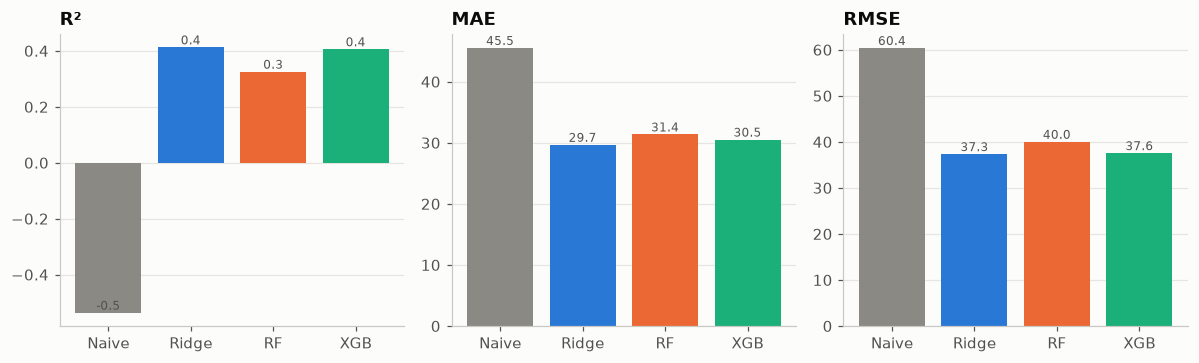

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
colors = [C["gray"], C["blue"], C["orange"], C["aqua"]]
for ax, metric in zip(axes, ["R2", "MAE", "RMSE"]):
    vals = overall[metric]
    ax.bar(range(4), vals.values, color=colors)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Naive", "Ridge", "RF", "XGB"])
    ax.set_title(metric.replace("R2", "R²"))
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=C["ink2"])
fig.tight_layout(); fig.savefig(RESULTS / "fig09_model_metrics.png", dpi=150); plt.show()

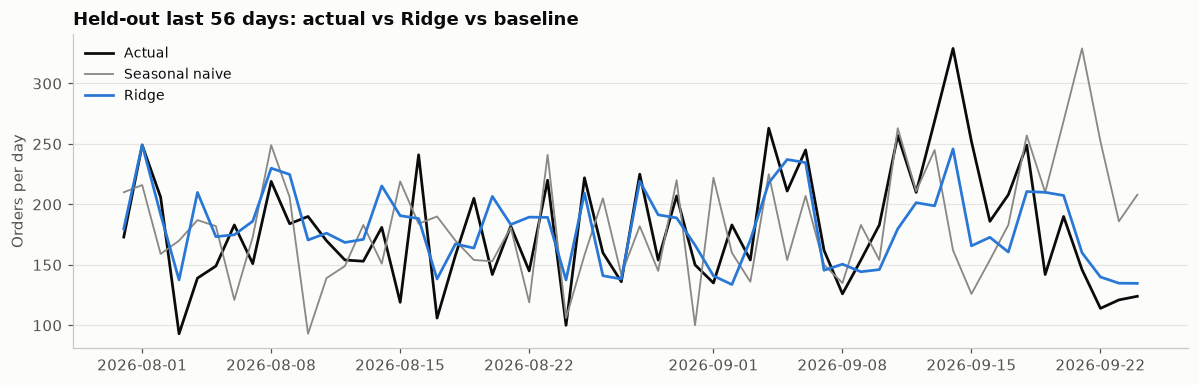

Best model by MAE: Ridge


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(yte.index, yte, color=C["ink"], label="Actual", lw=1.8)
best = overall["MAE"].drop("Seasonal naive").idxmin()
ax.plot(yte.index, preds["Seasonal naive"], color=C["gray"], lw=1.2, label="Seasonal naive")
ax.plot(yte.index, preds[best], color=C["blue"], lw=1.8, label=best)
ax.set_title(f"Held-out last 56 days: actual vs {best} vs baseline"); ax.set_ylabel("Orders per day"); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "fig10_actual_vs_pred.png", dpi=150); plt.show()
print("Best model by MAE:", best)

### Where does each model do well or badly?
Accuracy split by weather regime (rainy / hot / normal days) and by day type. A model that is only good on average can
still be poor on the rainy days the business cares about.

In [7]:
ctx = daily.loc[Xte.index]
seg_regime = predict.score_table(yte, preds, by=ctx["regime"])
seg_regime.round(2).to_csv(RESULTS / "model_metrics_by_regime.csv")
seg_regime.round(2)

n    R2    MAE      MSE   RMSE  MAPE_%   bias
model          segment                                                
Seasonal naive normal   21 -0.63  45.43  3439.05  58.64   34.72 -29.90
               rainy    29 -1.16  51.41  4465.83  66.83   26.77  15.28
               hot       6  0.80  17.33   414.00  20.35    9.77   4.33
Ridge          normal   21  0.36  30.06  1345.32  36.68   20.39  -5.17
               rainy    29  0.29  29.79  1465.24  38.28   15.85  -1.42
               hot       6  0.42  27.73  1222.28  34.96   14.38  19.56
Random Forest  normal   21  0.34  31.69  1387.01  37.24   21.65  -7.77
               rainy    29  0.13  31.70  1800.42  42.43   16.72  -2.53
               hot       6  0.34  28.61  1385.42  37.22   14.34  20.50
XGBoost        normal   21  0.34  31.93  1379.89  37.15   22.09  -7.95
               rainy    29  0.29  30.31  1474.95  38.41   15.76   1.58
               hot       6  0.43  26.57  1202.57  34.68   13.55  17.62

In [8]:
day_type = pd.Series(np.where(ctx["dow"].isin([4, 5, 6]), "Fri-Sun", "Mon-Thu"), index=ctx.index)
seg_day = predict.score_table(yte, preds, by=day_type)
seg_day.round(2)

n    R2    MAE      MSE   RMSE  MAPE_%  bias
model          segment                                               
Seasonal naive Fri-Sun  24 -0.01  33.75  1732.50  41.62   18.44 -0.17
               Mon-Thu  32 -1.39  54.34  5082.28  71.29   35.04 -4.84
Ridge          Fri-Sun  24  0.09  31.93  1551.40  39.39   17.08 -0.96
               Mon-Thu  32  0.40  27.97  1276.36  35.73   17.63 -0.30
Random Forest  Fri-Sun  24 -0.02  33.77  1739.40  41.71   18.64 -6.51
               Mon-Thu  32  0.30  29.56  1497.07  38.69   18.06  1.33
XGBoost        Fri-Sun  24  0.08  32.83  1574.14  39.68   17.60 -1.02
               Mon-Thu  32  0.39  28.78  1287.10  35.88   18.12  0.29

### Residuals

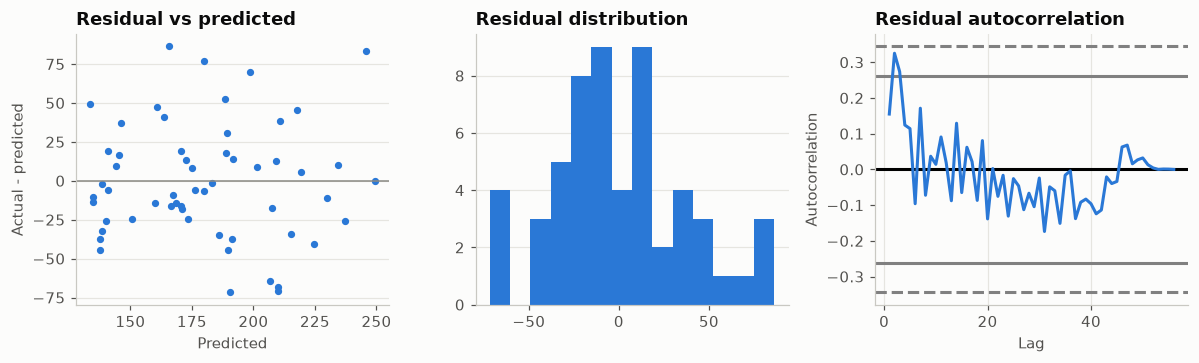

Residual mean -0.58, sd 37.67; Ljung-Box p (lag 7) = 0.019


In [9]:
res = (yte - preds[best])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].scatter(preds[best], res, s=14, color=C["blue"]); axes[0].axhline(0, color=C["gray"], lw=1)
axes[0].set_title("Residual vs predicted"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual - predicted")
axes[1].hist(res, bins=14, color=C["blue"]); axes[1].set_title("Residual distribution")
pd.plotting.autocorrelation_plot(res, ax=axes[2], color=C["blue"]); axes[2].set_title("Residual autocorrelation")
fig.tight_layout(); fig.savefig(RESULTS / "fig11_residuals.png", dpi=150); plt.show()
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(res, lags=[7], return_df=True)
print(f"Residual mean {res.mean():.2f}, sd {res.std():.2f}; Ljung-Box p (lag 7) = {lb['lb_pvalue'].iloc[0]:.3f}")

### Which inputs matter?
Permutation importance on the held-out set (increase in MAE when one feature is shuffled; model-agnostic and honest
about correlated features), and SHAP values for the XGBoost model.

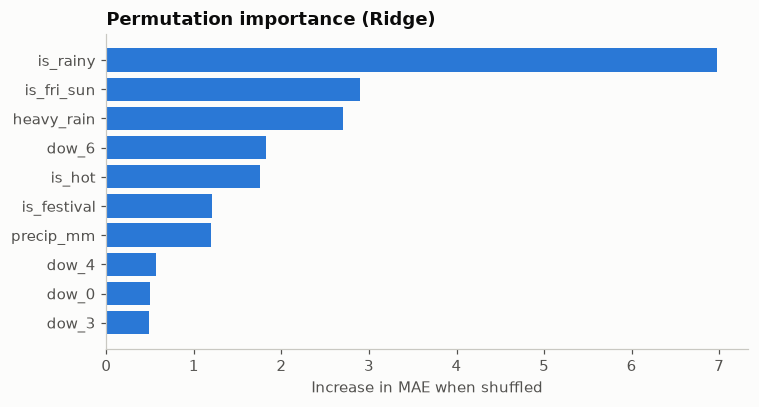

is_rainy       6.98
is_fri_sun     2.90
heavy_rain     2.70
dow_6          1.83
is_hot         1.75
is_festival    1.21
precip_mm      1.20
dow_4          0.57
dow_0          0.50
dow_3          0.48
dtype: float64

In [10]:
from sklearn.inspection import permutation_importance
model = fitted[best]
pi = permutation_importance(model, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=30, random_state=predict.SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
imp.round(2).to_csv(RESULTS / "model_feature_importance.csv", header=["MAE_increase"])
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(top.index, top.values, color=C["blue"]); ax.set_xlabel("Increase in MAE when shuffled")
ax.set_title(f"Permutation importance ({best})"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(RESULTS / "fig12_importance.png", dpi=150); plt.show()
imp.head(10).round(2)

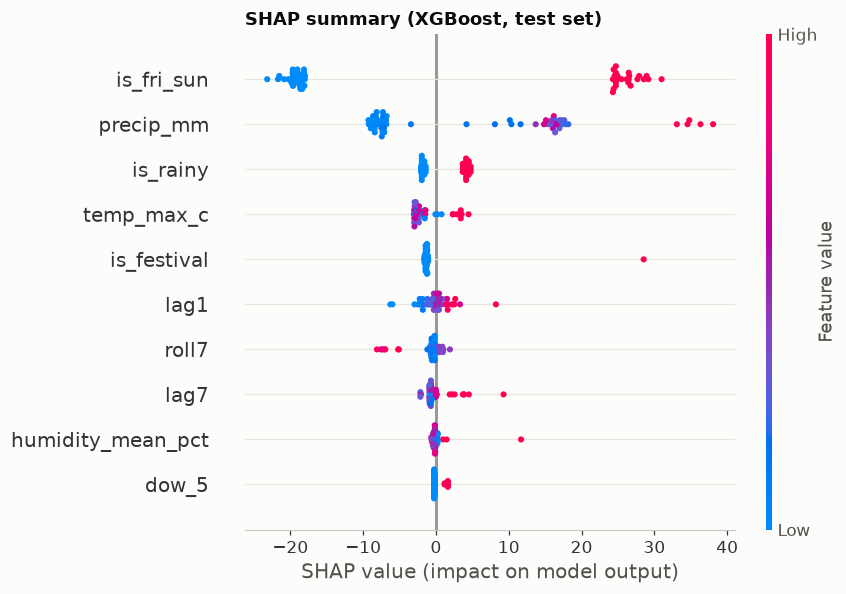

In [11]:
import shap
explainer = shap.TreeExplainer(fitted["XGBoost"])
sv = explainer.shap_values(Xte)
shap.summary_plot(sv, Xte, show=False, max_display=10)
plt.title("SHAP summary (XGBoost, test set)"); plt.tight_layout()
plt.savefig(RESULTS / "fig13_shap.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Effect of weather and the planning view

In [12]:
no_weather_cols = [c for c in X.columns if c not in predict.WEATHER_FEATURES and not c.startswith("phase_")]
_, p_nw = predict.fit_and_predict(Xtr[no_weather_cols], ytr, Xte[no_weather_cols])
rows = []
for m in ["Ridge", "Random Forest", "XGBoost"]:
    rows.append({"model": m, "MAE with weather": predict.score(yte, preds[m])["MAE"],
                 "MAE without weather": predict.score(yte, p_nw[m])["MAE"]})
weather_effect = pd.DataFrame(rows).set_index("model")
weather_effect["improvement_%"] = (1 - weather_effect["MAE with weather"] / weather_effect["MAE without weather"]) * 100
weather_effect.round(2).to_csv(RESULTS / "model_weather_effect.csv")
weather_effect.round(2)

,MAE with weather,MAE without weather,improvement_%
model,,,
Ridge,29.67,31.83,6.80
Random Forest,31.37,33.13,5.34
XGBoost,30.52,31.54,3.25


In [13]:
q90 = float(res.abs().quantile(0.90))
print(f"{best}: on 90% of held-out days the prediction was within +/- {q90:.0f} orders "
      f"({q90 / yte.mean() * 100:.0f}% of the mean daily volume of {yte.mean():.0f}).")

Ridge: on 90% of held-out days the prediction was within +/- 69 orders (38% of the mean daily volume of 180).


In [14]:
# Noise floor implied by the generator: daily counts are Negative Binomial with r = 25, so even a model that knows the
# true expected value cannot beat sd = sqrt(mu + mu^2 / r) per day.
R_DISP = 25
mu = yte.mean()
print(f"Irreducible sd at the test-period mean ({mu:.0f} orders/day): {np.sqrt(mu + mu**2 / R_DISP):.1f}  "
      f"vs best-model RMSE {overall.loc[best, 'RMSE']:.1f}")

Irreducible sd at the test-period mean (180 orders/day): 38.4  vs best-model RMSE 37.3


## 5. First findings
1. **Every model beats the baseline.** On the 56 held-out days Ridge has MAE 29.7 against 45.5 for the seasonal-naive
   baseline (about 35% lower); RMSE falls from 60.4 to 37.3. Ridge, XGBoost and Random Forest are within about 2 orders
   of MAE of each other, so the model family matters much less than the choice of inputs.
2. **Rain is the strongest signal.** The rainy-day flag has by far the largest permutation importance (about +7 MAE when
   shuffled), ahead of Fri-Sun (+2.9) and heavy rain (+2.7). Rainy days average about 203 orders against 161 on normal days
   in the generated data, and the models pick that up. Removing the weather and monsoon inputs raises MAE by 3 to 7%.
3. **Errors are close to the noise floor.** The generator draws daily counts with extra randomness (Negative Binomial,
   r = 25), which caps accuracy at an RMSE of about 38 orders at this volume. The best model's RMSE is 37, so there is
   little left to gain from more tuning. A MAPE near 17% reflects that noise, not a weak model.
4. **Yesterday's orders barely help.** `lag1` and `lag7` have near-zero importance because the generator has no day-to-day
   memory. Real restaurant data would normally have it, so this finding should not be generalised beyond the synthetic data.
5. **Business reading.** Plan staffing and stock from the day of week and the rain forecast. On 90% of held-out days the
   prediction was within about 70 orders (roughly 38% of daily volume), so a buffer of that size is needed to cover
   most days.

**Limits.**
- The hot-day segment has only 6 test days, too few to compare models there.
- Residuals show mild weekly autocorrelation (Ljung-Box p = 0.02 at lag 7), a small structure the models do not capture.
- Weather is observed, not forecast, so these errors are an upper bound on what a live system could achieve.
- Results come from one chronological split.